# Milestone 3 Data visualization

## Task 1: Monthly Revenue Trend Chart

In [15]:
# Setup

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

df = pd.read_excel("../data/Coffee Shop Sales.xlsx")
df["line_revenue"] = df["transaction_qty"] * df["unit_price"]
df["month"] = pd.to_datetime(df["transaction_date"]).dt.to_period('M')
df["time_of_day"] = df["transaction_time"].apply(lambda t: t.hour)



month
2023-01     81677.74
2023-02     76145.19
2023-03     98834.68
2023-04    118941.08
2023-05    156727.76
2023-06    166485.88
Freq: M, Name: line_revenue, dtype: float64

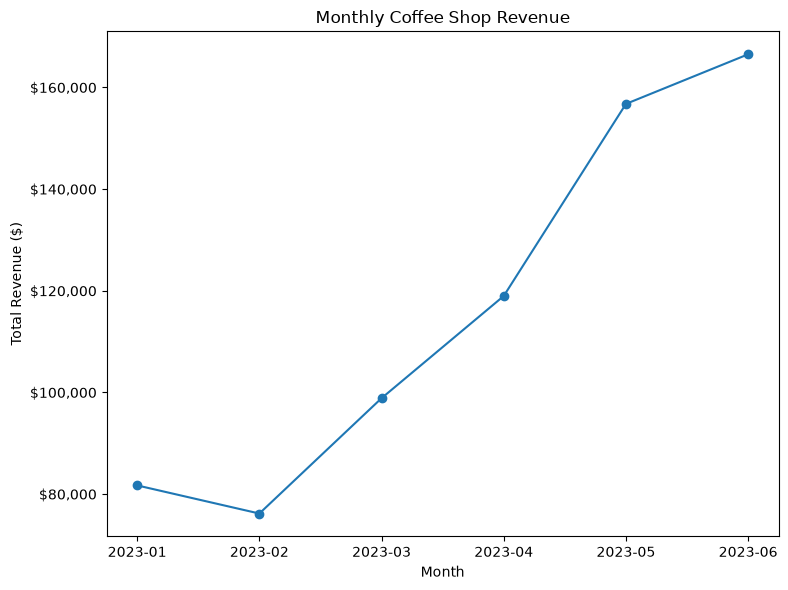

In [16]:
# Task 1: Monthly Revenue Trend Chart

total_revenue_monthly = df.groupby("month")["line_revenue"].sum().sort_index()
display(total_revenue_monthly)

plt.figure(figsize=(8, 6))

plt.plot(
    total_revenue_monthly.index.astype(str),
    total_revenue_monthly.values,
    marker="o"
)

plt.title("Monthly Coffee Shop Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")

# Step 5: Format the Y-axis as dollars
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)


# Step 6: Display the chart
plt.tight_layout()
plt.show()


In [68]:
monthly_comparison = total_revenue_monthly.to_frame(name = "revenue").reset_index()
monthly_comparison["calendar_days"] = monthly_comparison["month"].dt.days_in_month
monthly_comparison["revenue_per_day"] = monthly_comparison["revenue"]/monthly_comparison["calendar_days"]
monthly_comparison["revenue_change_pct"] = (
    monthly_comparison["revenue"].pct_change() * 100
)
monthly_comparison["daily_revenue_change_pct"] = (
    monthly_comparison["revenue_per_day"].pct_change() * 100
)
monthly_comparison



,month,revenue,calendar_days,revenue_per_day,revenue_change_pct,daily_revenue_change_pct
0,2023-01,81677.74,31,2634.765806,NaN,NaN
1,2023-02,76145.19,28,2719.471071,-6.773633,3.214907
2,2023-03,98834.68,31,3188.215484,29.797667,17.236602
3,2023-04,118941.08,30,3964.702667,20.343466,24.354915
4,2023-05,156727.76,31,5055.734194,31.769242,27.518622
5,2023-06,166485.88,30,5549.529333,6.226159,9.767031


### How did total revenue change from January to February, in dollars and percentage terms?

The revenue from January to February changed from $81677 to $76145. This is a percentage change in revenue of -6.77% and a percentage change of 3.21% in daily revenue.

### How many calendar days were in each month, and why does this matter when comparing monthly totals?

Different month lengths affect the time available to generate revenue. Comparing revenue per day helps account for that difference. Month length alone doesn’t determine the daily sales rate.

### What was the average revenue per calendar day in each month, and what was the percentage change?

The average revenue per day From January to June was $2634, $2719, $3188, $3964, $5055, and $5549 respectively.

### How can February have lower total revenue but higher revenue per calendar day? What does each measure tell management?

Monthly total: how much revenue the business generated during the whole month.
Revenue per calendar day: the average daily sales rate, accounting for different month lengths.
Thus, while February had a higher daily sales rate, because it had less days compared to January, it had lower total sales.

### How would you describe the overall January–June revenue trend while accurately acknowledging the February exception?

Overall, when judging by revenue per day, there is a consistent positive upward trend in revenue from January to June. But since, February had total less days compared to January, it resulted in a less total revenue.

## Task 2: Coffee Shop Revenue by Location Chart

store_location
Lower Manhattan    230057.25
Astoria            232243.91
Hell's Kitchen     236511.17
Name: line_revenue, dtype: float64

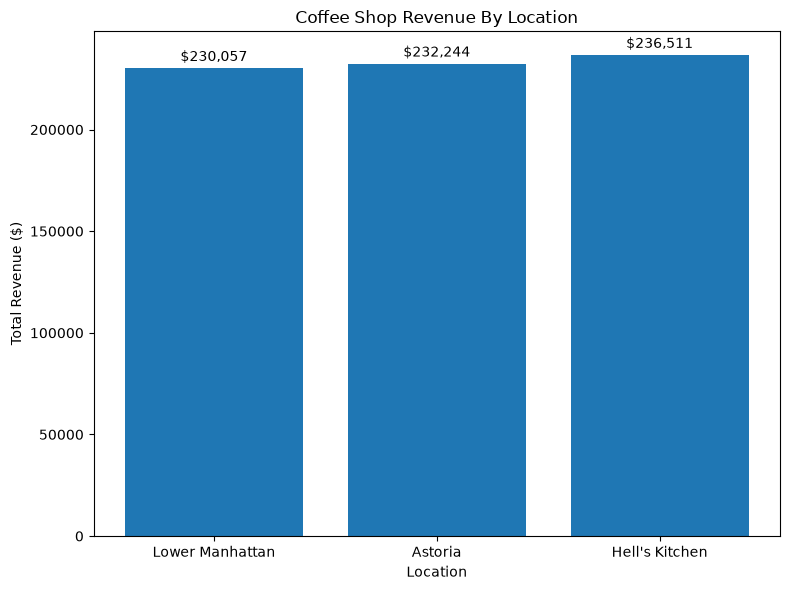

In [17]:
revenue_by_location = df.groupby("store_location")["line_revenue"].sum().sort_values()
display(revenue_by_location)

plt.figure(figsize=(8, 6))

bars = plt.bar(
    revenue_by_location.index,
    revenue_by_location.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_location.values],
    padding=3
)

plt.title("Coffee Shop Revenue By Location")
plt.xlabel("Location")
plt.ylabel("Total Revenue ($)")


plt.tight_layout()
plt.show()


### Which store generates the highest revenue?
The store with the highest revenue is Hell's Kitchen.


### What is the dollar difference between the highest- and lowest-performing stores?
The dollar difference is approx. $6000.


### Does the highest-revenue store necessarily have the most transactions?
Not necessarily, it depends on the price of the products, too.

## Task 3: Top 10 Products by Revenue Chart

Text(0, 0.5, 'Product')

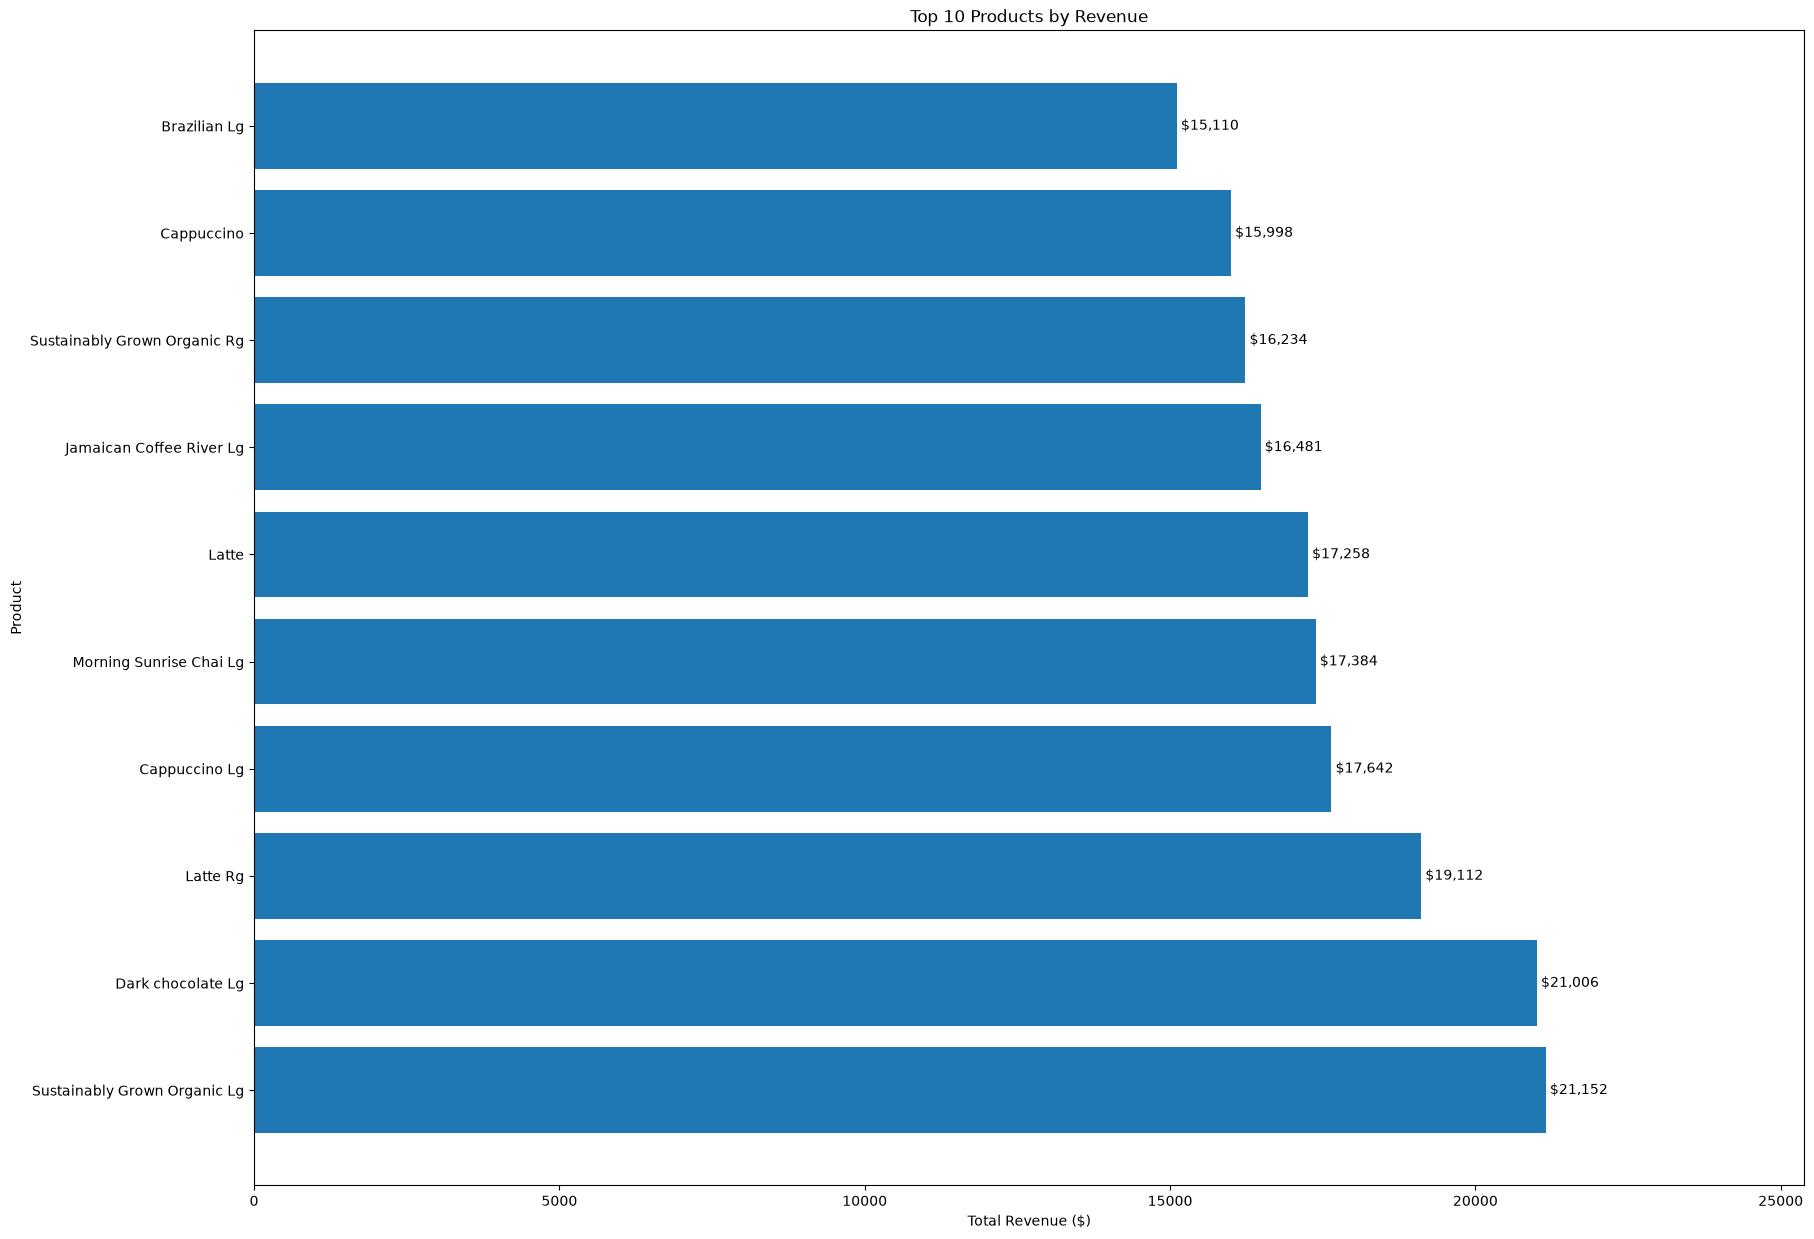

In [54]:
revenue_by_product = df.groupby("product_detail")["line_revenue"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(20, 15))

bars = plt.barh(
    revenue_by_product.index,
    revenue_by_product.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_product.values],
    padding=3
)

plt.xlim(0, revenue_by_product.max() * 1.2)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product")



### Which individual product generates the most revenue?
The Barista Esperesso generates the most revenue, at $91K.


### How much revenue does it generate compared with the 10th-ranked product?
Compared to the drip coffee, the Barista Espresso generates about $60K more.


### Does generating the most revenue necessarily mean a product sells the most units?
Not necessarily; it also depends on how much each product sells for per unit.

## Task 4: Busiest Hours by Store Chart

,store_location,time_of_day,transactions
3,Astoria,10,5291
2,Astoria,9,5083
1,Astoria,8,4966
0,Astoria,7,4181
9,Astoria,16,3599
12,Astoria,19,3565
11,Astoria,18,3463
6,Astoria,13,3456
5,Astoria,12,3438
8,Astoria,15,3423


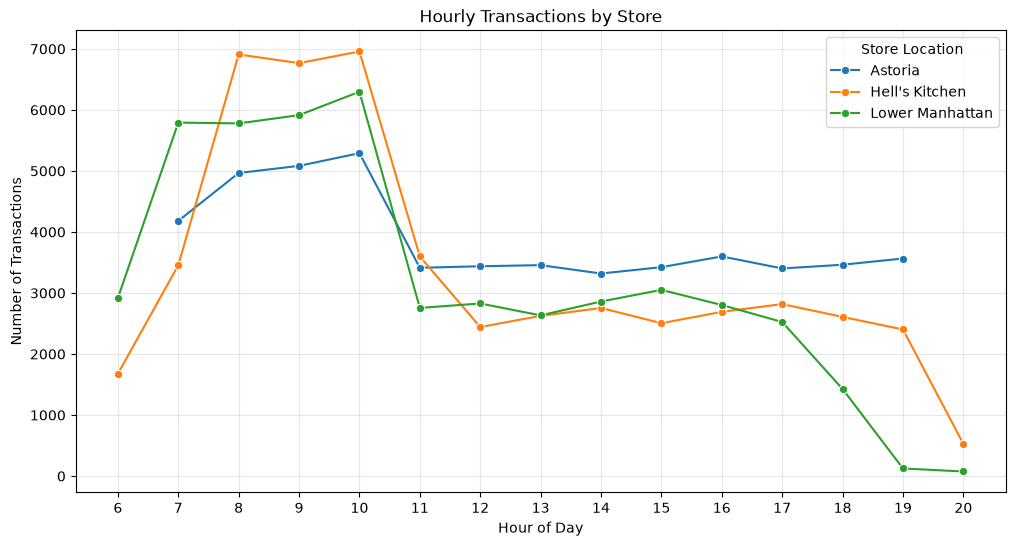

In [30]:
store_hour = (
    df.groupby(["store_location", "time_of_day"])["transaction_id"]
    .nunique()
    .reset_index(name="transactions")
    .sort_values(
        by=["store_location", "transactions"],
        ascending=[True, False]
    ) 
)

display(store_hour)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=store_hour,
    x="time_of_day",
    y="transactions",
    hue="store_location",
    marker="o"
)

plt.title("Hourly Transactions by Store")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")

plt.xticks(sorted(store_hour["time_of_day"].unique()))
plt.legend(title="Store Location")
plt.grid(alpha=0.3)

### Which store has the highest peak-hour transaction count?
Hell's Kitchen has the highest amount of transactions per hour at 10 am.


### Do all three locations experience their busiest period around the same time?
All three locations generally follow the pattern of high activity in late morning with a steep drop around noon that continues to the end of the day.


### Which store experiences the sharpest decline after its morning peak?
Lower Manhatten has the sharpest decine after its morning peak, dropping from around 6200 transactions to about 2800 transactions.


### What staffing recommendation would you make based on these patterns?
More staff available or on standby especially during the peak morning hours could be an idea worth looking into to ensure customers are best catered to and revenue is maximized.

## Task 5: Revenue Share by Product Category

Text(0, 0.5, 'Product Category')

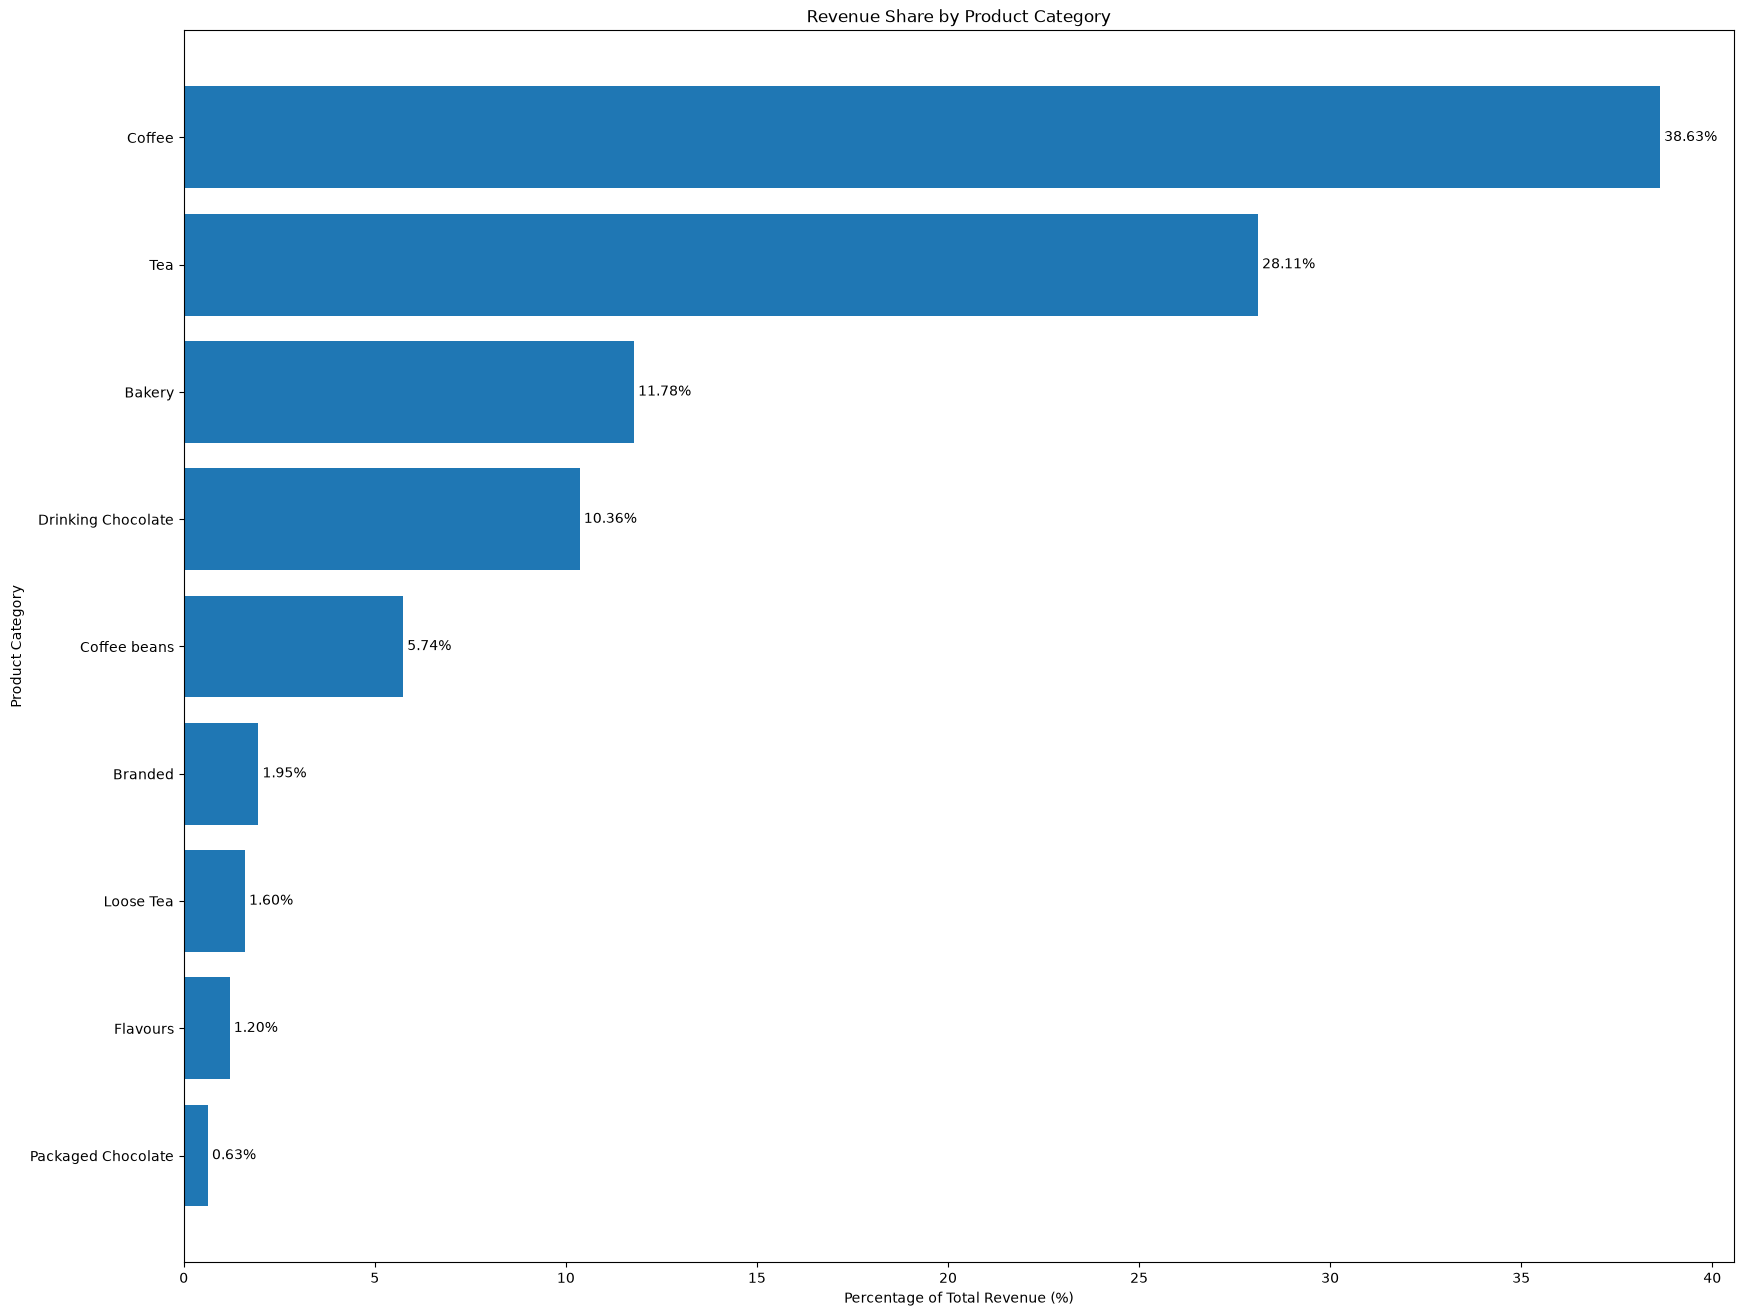

In [47]:
temp = df.groupby("product_category")["line_revenue"].sum().sort_values(ascending=False)
temp = temp.to_frame(name = "revenue")
temp["percentage"] = (
    temp["revenue"] / temp["revenue"].sum() * 100
).round(2)
temp = temp.sort_values(by = "percentage")
# Create the chart
plt.figure(figsize=(20, 16))

bars = plt.barh(
    temp.index,
    temp["percentage"]
)

plt.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in temp["percentage"]],
    padding=3
)

# Add chart title and axis labels
plt.title("Revenue Share by Product Category")
plt.xlabel("Percentage of Total Revenue (%)")
plt.ylabel("Product Category")


### Which category contributes the most revenue?
Coffee is the largest revenue-generating category, contributing $269,952.45, or 38.63% of total sales revenue.

### What percentage of revenue comes from Coffee and Tea combined?
Coffee and Tea collectively account for 66.74% of total revenue, making them the business's two dominant product categories.

### What does this suggest about the business's dependence on those two categories?
The business heavily depends on its coffee and tea sales for more than half of its revenue.

* With 66.74% of revenue concentrated in Coffee and Tea, Maven Roasters has significant exposure to changes in demand, pricing, or supply availability within these categories. Maintaining reliable inventory and monitoring sales trends in these products should therefore be a priority.

### What recommendation would you make to management?
Look more into resource allocation and opportunities in increasing revenue in those product categories.
* Management should prioritize inventory availability for high-demand Coffee and Tea products, particularly during peak operating hours. The company should also evaluate opportunities to bundle these beverages with Bakery items to increase average transaction value. Before implementing these changes, management should analyze profit margins, inventory turnover, and purchasing patterns to determine which actions are most financially beneficial.